# Welcome!
Below, we will learn to implement and train a policy to play atari-pong, using only the pixels as input. We will use convolutional neural nets, multiprocessing, and pytorch to implement and train our policy. Let's get started!

In [3]:
#restart the kernel once after install this package
!pip install 'gym<0.23.1'
!pip install 'gym[atari, accept-rom-license]'

Defaulting to user installation because normal site-packages is not writeable
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 624.4/624.4 kB 10.9 MB/s eta 0:00:00a 0:00:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for gym: filename=gym-0.23.0-py3-none-any.whl size=697740 sha256=ff09cfffb1853293de38d391a14722329e99ef4839643f792d6a9decfc09db14
  Stored in directory: /home/student/.cache/pip/wheels/3d/6f/b4/3991d4fae11d0ecb0754c11cc1b4e7745012850da4efaaf0b1
Successfully built gym
Defaulting to user installation because normal site-packages is not writeable
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 19.8 MB/s eta 0:00:0000:010:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 434.7/434.7 kB 50.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for AutoROM.acc

In [1]:
# install package for displaying animation
!pip install JSAnimation

# custom utilies for displaying animation, collecting rollouts and more
import pong_utils

%matplotlib inline

# check which device is being used. 
# I recommend disabling gpu until you've made sure that the code runs
device = pong_utils.device
print("using device: ",device)

Defaulting to user installation because normal site-packages is not writeable
using device:  cuda:0


In [2]:
# render ai gym environment
import gym
import time

# PongDeterministic does not contain random frameskip
# so is faster to train than the vanilla Pong-v4 environment
env = gym.make('PongDeterministic-v4')

print("List of available actions: ", env.unwrapped.get_action_meanings())

# we will only use the actions 'RIGHTFIRE' = 4 and 'LEFTFIRE" = 5
# the 'FIRE' part ensures that the game starts again after losing a life
# the actions are hard-coded in pong_utils.py

List of available actions:  ['NOOP', 'FIRE', 'RIGHT', 'LEFT', 'RIGHTFIRE', 'LEFTFIRE']


A.L.E: Arcade Learning Environment (version 0.7.5+db37282)
[Powered by Stella]


# Preprocessing
To speed up training, we can simplify the input by cropping the images and use every other pixel



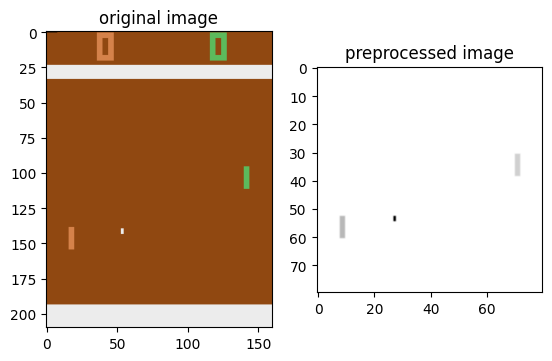

In [3]:
import matplotlib
import matplotlib.pyplot as plt

# show what a preprocessed image looks like
env.reset()
_, _, _, _ = env.step(0)
# get a frame after 20 steps
for _ in range(20):
    frame, _, _, _ = env.step(1)

plt.subplot(1,2,1)
plt.imshow(frame)
plt.title('original image')

plt.subplot(1,2,2)
plt.title('preprocessed image')

# 80 x 80 black and white image
plt.imshow(pong_utils.preprocess_single(frame), cmap='Greys')
plt.show()



# Policy

## Exercise 1: Implement your policy
 
Here, we define our policy. The input is the stack of two different frames (which captures the movement), and the output is a number $P_{\rm right}$, the probability of moving left. Note that $P_{\rm left}= 1-P_{\rm right}$

In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F



# set up a convolutional neural net
# the output is the probability of moving right
# P(left) = 1-P(right)
class Policy(nn.Module):

    def __init__(self):
        super(Policy, self).__init__()
        
        
    ########
    ## 
    ## Modify your neural network
    ##
    ########
        
        # 80x80 to outputsize x outputsize
        # outputsize = (inputsize - kernel_size + stride)/stride 
        # (round up if not an integer)

        # output = 20x20 here
        self.conv = nn.Conv2d(2, 1, kernel_size=4, stride=4)
        self.size=1*20*20
        
        # 1 fully connected layer
        self.fc = nn.Linear(self.size, 1)
        self.sig = nn.Sigmoid()
        
    def forward(self, x):
        
    ########
    ## 
    ## Modify your neural network
    ##
    ########
    
        x = F.relu(self.conv(x))
        # flatten the tensor
        x = x.view(-1,self.size)
        return self.sig(self.fc(x))


# run your own policy!
# policy=Policy().to(device)
policy=pong_utils.Policy().to(device)

# we use the adam optimizer with learning rate 2e-4
# optim.SGD is also possible
import torch.optim as optim
optimizer = optim.Adam(policy.parameters(), lr=1e-4)

# Game visualization
pong_utils contain a play function given the environment and a policy. An optional preprocess function can be supplied. Here we define a function that plays a game and shows learning progress

In [6]:
from IPython.display import HTML, display
import matplotlib.pyplot as plt
from matplotlib import animation


def animate_frames_fixed(frames):
    fig = plt.figure()

    patch = plt.imshow(frames[0])

    anim = animation.FuncAnimation(
        fig,
        lambda i: patch.set_data(frames[i]),
        frames=len(frames),
        interval=30
    )

    plt.close(fig)

    display(
        HTML(anim.to_jshtml(default_mode="once"))
    )


pong_utils.animate_frames = animate_frames_fixed

In [7]:
pong_utils.play(env, policy, time=200) 
# try to add the option "preprocess=pong_utils.preprocess_single"
# to see what the agent sees

# Function Definitions
Here you will define key functions for training. 

## Exercise 2: write your own function for training
(what I call scalar function is the same as policy_loss up to a negative sign)

### PPO
Later on, you'll implement the PPO algorithm as well, and the scalar function is given by
$\frac{1}{T}\sum^T_t \min\left\{R_{t}^{\rm future}\frac{\pi_{\theta'}(a_t|s_t)}{\pi_{\theta}(a_t|s_t)},R_{t}^{\rm future}{\rm clip}_{\epsilon}\!\left(\frac{\pi_{\theta'}(a_t|s_t)}{\pi_{\theta}(a_t|s_t)}\right)\right\}$

the ${\rm clip}_\epsilon$ function is implemented in pytorch as ```torch.clamp(ratio, 1-epsilon, 1+epsilon)```

In [10]:
def clipped_surrogate(policy, old_probs, states, actions, rewards,
                      discount = 0.995, epsilon=0.1, beta=0.01):

    ########
    ## 
    ## WRITE YOUR OWN CODE HERE
    ##
    ########

    old_probs = torch.as_tensor(
        old_probs,
        dtype=torch.float32,
        device=device
    ).detach()
    
    actions = torch.tensor(actions, dtype=torch.int8, device=device)

    # Compute discounted future rewards
    rewards = np.asarray(rewards, dtype=np.float32)

    discounted_rewards = np.zeros_like(
        rewards,
        dtype=np.float32
    )

    running_return = np.zeros_like(
        rewards[-1],
        dtype=np.float32
    )

    for t in reversed(range(len(rewards))):
        # In Pong, nonzero rewards indicate the end of a rally.
        # Do not propagate rewards across rally boundaries.
        running_return = np.where(
            rewards[t] != 0.0,
            0.0,
            running_return
        )

        running_return = (
            rewards[t]
            + discount * running_return
        )

        discounted_rewards[t] = running_return

    # Convert to PyTorch tensor
    discounted_rewards = torch.tensor(
        discounted_rewards,
        dtype=torch.float32,
        device=device
    )

    # Normalize returns across all collected samples.
    reward_mean = discounted_rewards.mean()

    reward_std = discounted_rewards.std(
        unbiased=False
    )

    discounted_rewards = (
        discounted_rewards - reward_mean
    ) / (
        reward_std + 1e-10
    )
    
    # convert states to policy (or probability)
    new_probs = pong_utils.states_to_prob(policy, states)
    # states_to_prob returns the probability of RIGHT.
    # Convert it into the probability of the action
    # that was actually selected.
    new_probs = torch.where(actions == pong_utils.RIGHT, new_probs, 1.0-new_probs)

    # Keep logarithms and divisions numerically stable.
    new_probs = torch.clamp(
        new_probs,
        min=1e-8,
        max=1.0 - 1e-8
    )

    old_probs = torch.clamp(
        old_probs,
        min=1e-8,
        max=1.0 - 1e-8
    )
    
    # Probability ratio:
    # pi_theta(a|s) / pi_theta_old(a|s)
    ratio = new_probs / old_probs

    # Unclipped objective:
    # r_t(theta) * A_t
    surrogate_1 = (
        ratio * discounted_rewards
    )

    # Limit the ratio to:
    # [1 - epsilon, 1 + epsilon]
    clipped_ratio = torch.clamp(
        ratio,
        min=1.0 - epsilon,
        max=1.0 + epsilon
    )

    # Clipped objective:
    # clip(r_t(theta), 1-epsilon, 1+epsilon) * A_t
    surrogate_2 = (
        clipped_ratio * discounted_rewards
    )

    # PPO uses the pessimistic/lower objective.
    clipped_objective = torch.minimum(
        surrogate_1,
        surrogate_2
    )
    
    # include a regularization term
    # this steers new_policy towards 0.5
    # prevents policy to become exactly 0 or 1 helps exploration
    # add in 1.e-10 to avoid log(0) which gives nan
    entropy = -(new_probs*torch.log(old_probs)+ \
        (1.0-new_probs)*torch.log(1.0-old_probs))

    return torch.mean(beta*entropy + clipped_objective)


# Training
We are now ready to train our policy!
WARNING: make sure to turn on GPU, which also enables multicore processing. It may take up to 45 minutes even with GPU enabled, otherwise it will take much longer!

In [ ]:
from parallelEnv import parallelEnv
import numpy as np
# keep track of how long training takes
# WARNING: running through all 800 episodes will take 30-45 minutes

# training loop max iterations
episode = 500

# widget bar to display progress
!pip install progressbar
import progressbar as pb
widget = ['training loop: ', pb.Percentage(), ' ', 
          pb.Bar(), ' ', pb.ETA() ]
timer = pb.ProgressBar(widgets=widget, maxval=episode).start()


envs = parallelEnv('PongDeterministic-v4', n=8, seed=1234)

discount_rate = .99
epsilon = 0.1
beta = .01
tmax = 320
SGD_epoch = 4

# keep track of progress
mean_rewards = []

for e in range(episode):

    # collect trajectories
    old_probs, states, actions, rewards = \
        pong_utils.collect_trajectories(envs, policy, tmax=tmax)
        
    total_rewards = np.sum(rewards, axis=0)


    # gradient ascent step
    for _ in range(SGD_epoch):
        
        # uncomment to utilize your own clipped function!
        L = -clipped_surrogate(policy, old_probs, states, actions, rewards, epsilon=epsilon, beta=beta)

        #L = -pong_utils.clipped_surrogate(policy, old_probs, states, actions, rewards, epsilon=epsilon, beta=beta)
        optimizer.zero_grad()
        L.backward()
        optimizer.step()
        del L
    
    # the clipping parameter reduces as time goes on
    epsilon*=.999
    
    # the regulation term also reduces
    # this reduces exploration in later runs
    beta*=.995
    
    # get the average reward of the parallel environments
    mean_rewards.append(np.mean(total_rewards))
    
    # display some progress every 20 iterations
    if (e+1)%20 ==0 :
        print("Episode: {0:d}, score: {1:f}".format(e+1,np.mean(total_rewards)))
        print(total_rewards)
        
    # update progress widget bar
    timer.update(e+1)
    
timer.finish()

Defaulting to user installation because normal site-packages is not writeable


Episode: 20, score: -13.375000
[-16. -15. -14. -12. -10. -13. -13. -14.]


Episode: 40, score: -12.875000
[-16. -16. -12. -14.  -8. -10. -16. -11.]


Episode: 60, score: -14.500000
[-12. -15. -13. -15. -14. -16. -15. -16.]


Episode: 80, score: -15.500000
[-16. -16. -16. -15. -14. -15. -15. -17.]


Episode: 100, score: -13.625000
[-10. -15. -15. -16. -11. -11. -16. -15.]


... (5 outputs left out)

Episode: 220, score: -6.375000
[-7. -5. -7. -4. -6. -9. -6. -7.]


Episode: 240, score: -5.500000
[-4. -3. -7. -4. -8. -4. -8. -6.]


Episode: 260, score: -4.625000
[-5. -5.  0. -6. -7. -7. -4. -3.]


Episode: 280, score: -4.625000
[ -3.  -5.  -1.  -3.  -5. -10.  -7.  -3.]


In [1]:
pong_utils.play(env, policy, time=200) 

NameError: name 'pong_utils' is not defined

In [ ]:
# save your policy!
torch.save(policy, 'PPO.policy')

# load policy if needed
# policy = torch.load('PPO.policy')

# try and test out the solution 
# make sure GPU is enabled, otherwise loading will fail
# (the PPO verion can win more often than not)!
#
# policy_solution = torch.load('PPO_solution.policy')
# pong_utils.play(env, policy_solution, time=2000) 